In [1]:
import pandas as pd
import numpy as np
import torch

In [2]:
human_kinome = pd.read_csv("../../data/human_kinome.csv")

In [3]:
uniprot2gene = {human_kinome["UniprotID"][i]:human_kinome["gene"][i] for i in range(human_kinome.shape[0])}

In [4]:
logits = pd.read_pickle("../../data/kinbertv1_pred/kinbertv1_covid-psite1_logit.pkl")

In [5]:
len(logits)

472

In [6]:
kinase = pd.read_pickle("../../data/kinbertv2_pred/kinbertv2_covid-psite1_kinasename.pkl")

In [7]:
substrate = pd.read_pickle("../../data/labeled_data/virus_psites/covid_psite_1_min.pkl")

In [8]:
substrate.shape[0]

44

In [9]:
logits[0].shape

(44, 2)

In [10]:
len(logits[0]) == substrate.shape[0]

True

In [12]:
len(logits) == len(kinase)

True

In [13]:
m = torch.nn.Softmax()
pred_res = []
pred_res_prob = []
for i in range(substrate.shape[0]):
    s = substrate.iloc[i,:]
    predicted_kinase_prob = np.array([float(m(torch.tensor(logits_curr[i]))[1]) for logits_curr in logits])
    predicted_kinase_logits = np.array([logits_curr[i][1] for logits_curr in logits])
    kinase_sorted_ind = np.flipud(np.argsort(predicted_kinase_logits)) 
    kinase_sorted_ind[0:10]
    pred_logit = predicted_kinase_logits[kinase_sorted_ind[0:10]]
    pred_prob = predicted_kinase_prob[kinase_sorted_ind[0:10]]
    sel_ind = (pred_prob>0.90)
    pred_kinase = [uniprot2gene[kinase[i]] for i in kinase_sorted_ind[0:10]]
    pred_kinase_prob = [pred_kinase[i] + ":" + "{:.2f}".format(pred_logit[i])+":"+ "{:.2f}".format(pred_prob[i]) for i in range(len(pred_kinase)) if sel_ind[i]]
    pred_kinase_self = [pred_kinase[i]  for i in range(len(pred_kinase)) if sel_ind[i]]
    pred_res.append(pred_kinase)
    pred_res_prob.append(pred_kinase_prob)
    

/opt/conda/lib/python3.11/site-packages/torch/nn/modules/module.py:1775: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


In [14]:
# pred_res_prob

In [15]:
len(pred_res)

44

In [16]:
substrate["pred_kinase"] = pred_res
substrate["pred_kinase_prob"] = pred_res_prob

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

In [18]:
res = [(elem.split(":")[0],float(elem.split(":")[1])) for elem in substrate["pred_kinase_prob"].iloc[0]]
res = pd.DataFrame(res)
res.columns = ["predicted kinase","logit score"]

In [19]:
res

,predicted kinase,logit score
0,SRPK2,3.27
1,NDR2,3.18
2,NDR1,3.14
3,PKACb,3.12
4,PKACg,3.11
5,MNK1,2.91
6,GSK3B,2.78
7,PKACa,2.63
8,SgK269,2.61
9,DMPK2,2.59


/tmp/ipykernel_13807/1392016732.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(res,x = "predicted kinase",y = "logit score",palette="pastel")


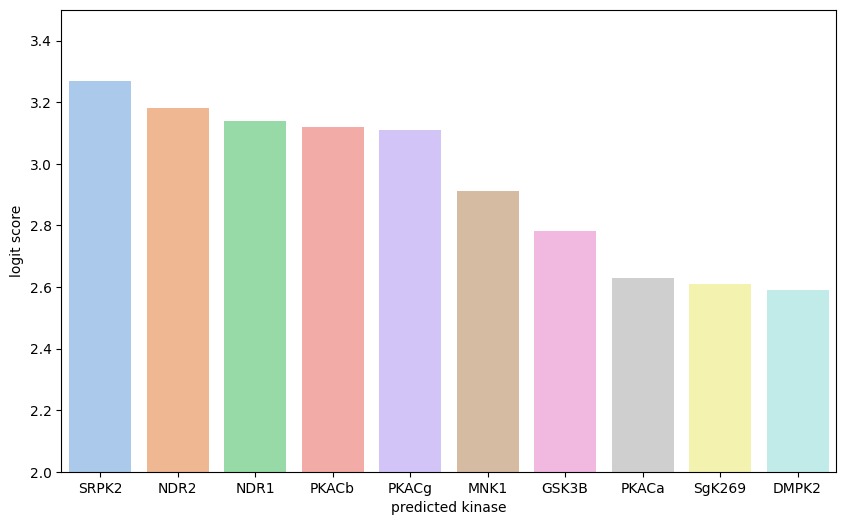

In [20]:
plt.figure(figsize=(10,6))
ax = sns.barplot(res,x = "predicted kinase",y = "logit score",palette="pastel")
ax.set_ylim((2,3.5))
plt.savefig('SRPK2.png')

/tmp/ipykernel_13807/1304547404.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(res,x = "predicted kinase",y = "logit score",palette="pastel")


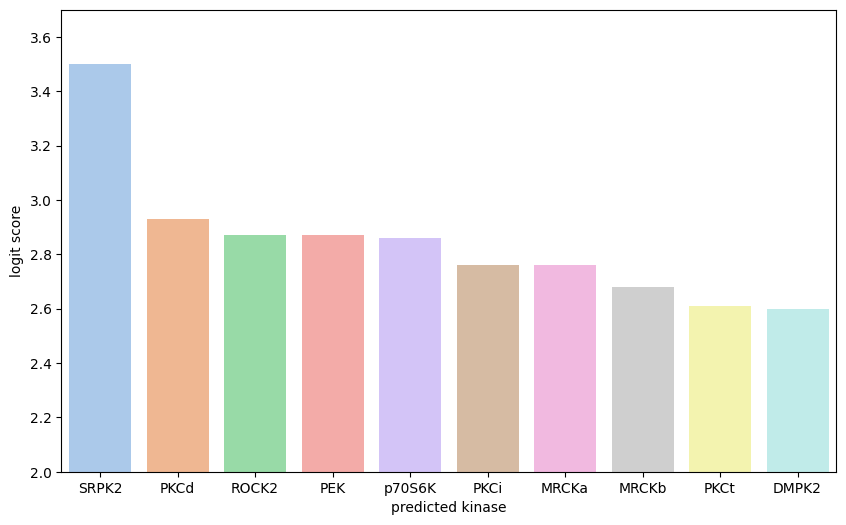

In [21]:
res = [(elem.split(":")[0],float(elem.split(":")[1])) for elem in substrate["pred_kinase_prob"].iloc[1]]
res = pd.DataFrame(res)
res.columns = ["predicted kinase","logit score"]
plt.figure(figsize=(10,6))
ax = sns.barplot(res,x = "predicted kinase",y = "logit score",palette="pastel")
ax.set_ylim((2,3.7))
plt.savefig('SRPK2.png')

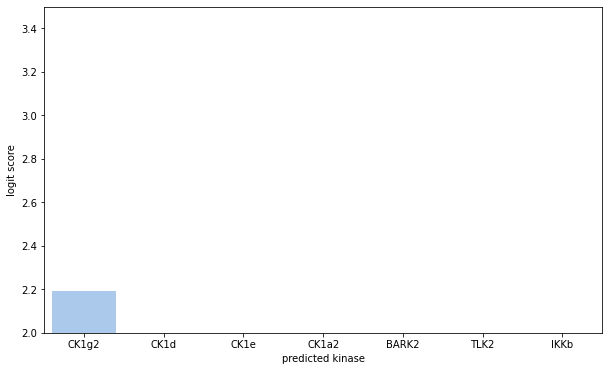

In [61]:
res = [(elem.split(":")[0],float(elem.split(":")[1])) for elem in substrate["pred_kinase_prob"].iloc[29]]
res = pd.DataFrame(res)
res.columns = ["predicted kinase","logit score"]
plt.figure(figsize=(10,6))
ax = sns.barplot(res,x = "predicted kinase",y = "logit score",palette="pastel")
ax.set_ylim((2,3.5))
plt.savefig('SRPK2.png')

In [22]:
substrate.apply(lambda s: s["substrate_seq"][int(s["p_ind"])-8:int(s["p_ind"])-1]+
                s["substrate_seq"][int(s["p_ind"])-1].lower()+ "*"+
                s["substrate_seq"][int(s["p_ind"]):int(s["p_ind"])+7],axis = 1)

0     AEGSRGGs*QASSRSS
1     SRGGSQAs*SRSSSRS
2     KGFYAEGs*RGGSQAS
3     RGGSQASs*RSSSRSR
4     TFGGPSDs*TGSNQNG
5     RNSSRNSt*PGSSRGT
6     SRNSTPGs*SRGTSPA
7     SSSRSRNs*SRNSTPG
8     RNSTPGSs*RGTSPAR
9     SRNSSRNs*TPGSSRG
10    ATEGALNt*PKDHIGT
11    PGSSRGTs*PARMAGN
12    SSRSRNSs*RNSTPGS
13    GQGVPINt*NSSPDDQ
14    TLKGGAPt*KVTFGDD
15    ARQGFVDs*DVETKDV
16    EDKAFQLt*PIAVQMT
17    PIILRLGs*PLSLNMA
18    MARKTLNs*LEDKAFQ
19    LRLGSPLs*LNMARKT
20    ITVATSRt*LSYYKLG
21    KLNTDHSs*SSDNIAL
22    MTYRRLIs*MMGFKMN
23    DNLKTLLs*LREVRTI
24    RSVYPVAs*PNECNQM
25    PATVSVSs*PDAVTAY
26    DRLNQLEs*KMSGKGQ
27    KKKKADEt*QALPQRQ
28    GSQASSRs*SSRSRNS
29    RITFGGPs*DSTGSNQ
30    GPSDSTGs*NQNGERS
31    TPGSSRGt*SPARMAG
32    SQASSRSs*SRSRNSS
33    QASSRSSs*RSRNSSR
34    KQLQQSMs*SADSTQA
35        QSMSSADs*TQA
36     QLQQSMSs*ADSTQA
37         SMSSADSt*QA
38    IGMEVTPs*GTWLTYT
39    NNVGPKVy*PIILRLG
40    VATSRTLs*YYKLGAS
41    NTDHSSSs*DNIALLV
42    PKEITVAt*SRTLSYY
43    CKFDE

In [23]:
substrate = substrate.loc[:,["substrate","p_ind","p_aa","pred_kinase","pred_kinase_prob"]]

In [24]:
substrate["p_ind"] = substrate["p_ind"].astype('int')

In [25]:
substrate["SPRK_pred"] = substrate["pred_kinase"].apply(lambda s: any(["SRPK" in elem for elem in s]))
substrate["CK1_pred"] = substrate["pred_kinase"].apply(lambda s: any(["CK1" in elem for elem in s]))
substrate["GSK_pred"] = substrate["pred_kinase"].apply(lambda s: any(["GSK3" in elem for elem in s]))

In [26]:
# sum(substrate["SPRK_pred"]+substrate["CK1_pred"]+substrate["GSK_pred"]>0)/44

In [27]:
covid_psite_1_refpred = pd.read_csv("../../data/labeled_data/virus_psites/covid_psite_1_pred.csv")

In [28]:
covid_psite_1_refpred["position"] = covid_psite_1_refpred["position"].astype('int')

In [29]:
substrate.loc[:,["substrate","p_ind","p_aa","pred_kinase_prob"]]

,substrate,p_ind,p_aa,pred_kinase_prob
0,NCAP_SARS2,180,S,"[SRPK2:3.27:1.00, NDR2:3.18:1.00, NDR1:3.14:1...."
1,NCAP_SARS2,183,S,"[SRPK2:3.50:1.00, PKCd:2.93:1.00, ROCK2:2.87:1..."
2,NCAP_SARS2,176,S,"[Erk3:1.67:0.97, RIPK3:1.51:0.96, TBCK:1.40:0...."
3,NCAP_SARS2,184,S,"[SRPK2:3.47:1.00, SgK269:3.04:1.00, PKCd:2.94:..."
4,NCAP_SARS2,23,S,"[CK1g3:3.21:1.00, CK1e:2.74:1.00, CK1d:2.65:1...."
5,NCAP_SARS2,198,T,"[CK1g3:3.12:1.00, DYRK1A:3.04:1.00, DYRK1B:3.0..."
6,NCAP_SARS2,201,S,"[SgK223:3.26:1.00, DYRK4:3.21:1.00, CK1g3:3.15..."
7,NCAP_SARS2,193,S,"[SRPK2:3.08:1.00, ROCK1:2.94:1.00, CLK2:2.93:1..."
8,NCAP_SARS2,202,S,"[MNK2:3.27:1.00, DYRK4:3.08:1.00, BUB1:3.07:1...."
9,NCAP_SARS2,197,S,"[LMR2:3.47:1.00, CRIK:3.31:1.00, MNK2:3.28:1.0..."


In [30]:
pd.merge(substrate.loc[substrate["substrate"]=="NCAP_SARS2",:],covid_psite_1_refpred,left_on = "p_ind",right_on = "position")

,substrate,p_ind,p_aa,pred_kinase,pred_kinase_prob,SPRK_pred,CK1_pred,GSK_pred,gene_symbol,Site,...,SITE_+/-7_AA,SRPK1,SRPK2,SRPK3,GSK3A,GSK3B,CK1A,CK1D,CK1E,CK1G1
0,NCAP_SARS2,180,S,"[SRPK2, NDR2, NDR1, PKACb, PKACg, MNK1, GSK3B,...","[SRPK2:3.27:1.00, NDR2:3.18:1.00, NDR1:3.14:1....",True,False,True,N,S180,...,AEGSRGGSQASSRSS,10.239764,7.354409,5.846753,108.419848,587.006234,14.188869,2.770747,11.853614,9.693859
1,NCAP_SARS2,176,S,"[Erk3, RIPK3, TBCK, ANKRD3, CK1g2, SgK288, MYO...","[Erk3:1.67:0.97, RIPK3:1.51:0.96, TBCK:1.40:0....",False,True,False,N,S176,...,KGFYAEGSRGGSQAS,0.636363,0.375051,0.876898,74.160133,409.127802,4.228635,0.656818,1.315093,3.513925
2,NCAP_SARS2,184,S,"[SRPK2, SgK269, PKCd, MNK1, PKCi, MAST1, MRCKb...","[SRPK2:3.47:1.00, SgK269:3.04:1.00, PKCd:2.94:...",True,False,False,N,S184,...,RGGSQASSRSSSRSR,3.785159,1.530480,1.763036,100.771453,130.847052,13.958240,4.957355,8.926015,20.317341
3,NCAP_SARS2,198,T,"[CK1g3, DYRK1A, DYRK1B, HIPK2, HIPK3, HIPK1, D...","[CK1g3:3.12:1.00, DYRK1A:3.04:1.00, DYRK1B:3.0...",False,True,False,N,T198,...,RNSSRNSTPGSSRGT,110.741582,19.906949,20.269701,344.485502,966.988476,6.667159,1.655080,2.397922,2.550267
4,NCAP_SARS2,201,S,"[SgK223, DYRK4, CK1g3, DYRK1A, CK1g2, SCYL1, D...","[SgK223:3.26:1.00, DYRK4:3.21:1.00, CK1g3:3.15...",False,True,False,N,S201,...,SRNSTPGSSRGTSPA,0.776549,0.464325,0.573576,197.043500,350.465613,7131.766009,260.092668,1633.112848,275.022320
5,NCAP_SARS2,193,S,"[SRPK2, ROCK1, CLK2, PKCi, MAP3K5, CLK4, YANK3...","[SRPK2:3.08:1.00, ROCK1:2.94:1.00, CLK2:2.93:1...",True,True,False,N,S193,...,SSSRSRNSSRNSTPG,2.202060,1.084181,1.460764,98.278936,864.210252,1122.303797,35.874085,167.305721,20.587124
6,NCAP_SARS2,202,S,"[MNK2, DYRK4, BUB1, SRPK2, Wee1B, SgK223, TRKC...","[MNK2:3.27:1.00, DYRK4:3.08:1.00, BUB1:3.07:1....",True,False,True,N,S202,...,RNSTPGSSRGTSPAR,1.036014,0.171979,0.522919,160.012117,248.139894,2.503568,0.840743,2.546207,1.006887
7,NCAP_SARS2,197,S,"[LMR2, CRIK, MNK2, SgK223, LMR1, ROCK1, RNAseL...","[LMR2:3.47:1.00, CRIK:3.31:1.00, MNK2:3.28:1.0...",True,True,False,N,S197,...,SRNSSRNSTPGSSRG,1.040440,0.696024,0.322461,86.250247,341.768406,8431.584724,91.836444,266.119271,33.507286
8,NCAP_SARS2,206,S,"[HIPK2, HIPK1, HIPK3, CRK7, SRPK2, CHED, CDK9,...","[HIPK2:3.12:1.00, HIPK1:3.11:1.00, HIPK3:3.08:...",True,False,False,N,S206,...,PGSSRGTSPARMAGN,368.237453,295.676677,253.028296,4.732384,7.715684,1.427217,3.301617,4.989599,0.941573
9,NCAP_SARS2,194,S,"[NDR2, MAST2, NDR1, DMPK1, p70S6K, MAST3, ROCK...","[NDR2:3.49:1.00, MAST2:3.45:1.00, NDR1:3.45:1....",False,False,False,N,S194,...,SSRSRNSSRNSTPGS,93.486366,22.513382,24.728879,138.983228,508.532507,3.282553,1.688471,4.874908,6.736583
